# Amazon Reviews Sentiment Analysis: Linear SVM
This notebook builds a Linear SVM that classifies Amazon reviews as positive or negative. It uses a random sample of 300,000 reviews from `train.ft.txt` (seed 42). The preprocessing pipeline comes first and the model comes after it.

In [1]:
%matplotlib inline
import os
import re
import random
import time
import joblib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix)

sns.set_theme(style="whitegrid")

SEED = 42
SAMPLE_SIZE = 300000
DATA_PATH = "../data/raw/train.ft.txt"
OUT_DIR = "../results/outputs"
EDA_DIR = "../results/eda_visualizations"
METRICS_DIR = "../results/final_metrics"

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(EDA_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

# stop here if the dataset is missing
assert os.path.exists(DATA_PATH), "train.ft.txt not found in data/raw/"

## 1. Loading the data

The raw file is sorted by product category, so taking the first rows would give a biased sample. A random sample of the whole file is used instead. Label 2 (positive) becomes 1 and label 1 (negative) becomes 0.

In [2]:
with open(DATA_PATH, "r", encoding="utf-8") as f:
    total_lines = sum(1 for _ in f)

# pick SAMPLE_SIZE random lines from the whole file
random.seed(SEED)
keep = set(random.sample(range(total_lines), SAMPLE_SIZE))

labels, texts = [], []
with open(DATA_PATH, "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i in keep:
            tag, _, text = line.strip().partition(" ")
            labels.append(1 if tag == "__label__2" else 0)
            texts.append(text)

df = pd.DataFrame({"label": labels, "text": texts})
print(f"full file: {total_lines:,} rows, working sample: {len(df):,} rows")
df.info()
df.head()

full file: 3,600,000 rows, working sample: 300,000 rows
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   label   300000 non-null  int64 
 1   text    300000 non-null  object
dtypes: int64(1), object(1)
memory usage: 4.6+ MB


,label,text
0,0,"Works, but not as advertised: I bought one of ..."
1,0,"Disappointed: I read the reviews,made my purch..."
2,0,Very Frustrating: My three year old son was ve...
3,1,"Kitchen TV: I bought this to replace a 13"" tub..."
4,1,Homer or Moses?: An extremely helpful gem on a...


## 2. Preprocessing pipeline

### 2.1 Missing values and duplicates

label    0
text     0
dtype: int64
dropped 0 rows with missing text
duplicate rows found: 0
rows left: 300000


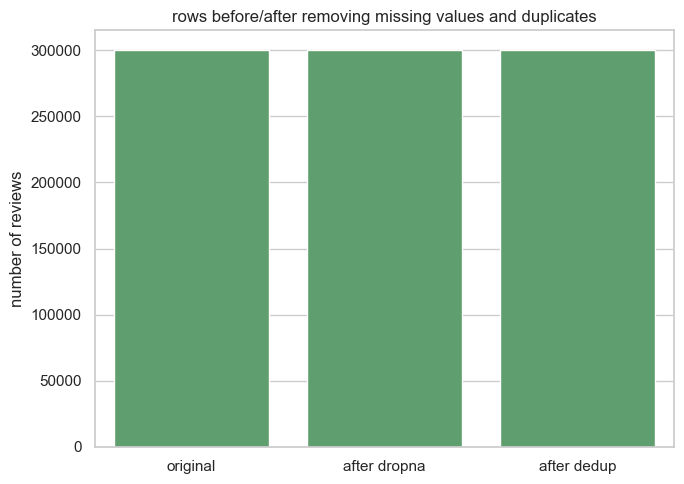

In [3]:
# an empty string is not found by isnull(), so change it to NaN first
df["text"] = df["text"].replace("", np.nan)
print(df.isnull().sum())

rows_start = len(df)
df = df.dropna(subset=["text"]).reset_index(drop=True)
rows_after_dropna = len(df)
print("dropped", rows_start - rows_after_dropna, "rows with missing text")

print("duplicate rows found:", df.duplicated(subset="text").sum())
df = df.drop_duplicates(subset="text").reset_index(drop=True)
rows_after_dedup = len(df)
print("rows left:", rows_after_dedup)

plt.figure(figsize=(7, 5))
sns.barplot(x=["original", "after dropna", "after dedup"],
            y=[rows_start, rows_after_dropna, rows_after_dedup], color="#55A868")
plt.title("rows before/after removing missing values and duplicates")
plt.ylabel("number of reviews")
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/missing_duplicate_cleanup.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.2 Text cleaning

The text is changed to lowercase and html tags, links, numbers and punctuation are removed. `word_count` is the number of words in the cleaned text.

In [4]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)             # html tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # links
    text = re.sub(r"[^a-z\s]", " ", text)          # keep letters only
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)
df["word_count"] = df["clean_text"].str.split().str.len()
df[["text", "clean_text", "word_count"]].head()

,text,clean_text,word_count
0,"Works, but not as advertised: I bought one of ...",works but not as advertised i bought one of th...,106
1,"Disappointed: I read the reviews,made my purch...",disappointed i read the reviews made my purcha...,52
2,Very Frustrating: My three year old son was ve...,very frustrating my three year old son was ver...,74
3,"Kitchen TV: I bought this to replace a 13"" tub...",kitchen tv i bought this to replace a tube tv ...,43
4,Homer or Moses?: An extremely helpful gem on a...,homer or moses an extremely helpful gem on a c...,74


### 2.3 Outlier removal

Reviews with an unusual length are removed using the IQR method on `word_count`.

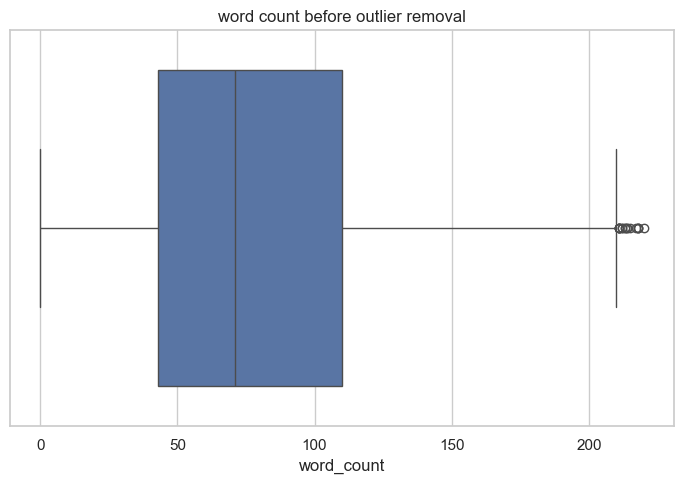

IQR bounds: [-57.5, 210.5] words, removed 17 rows


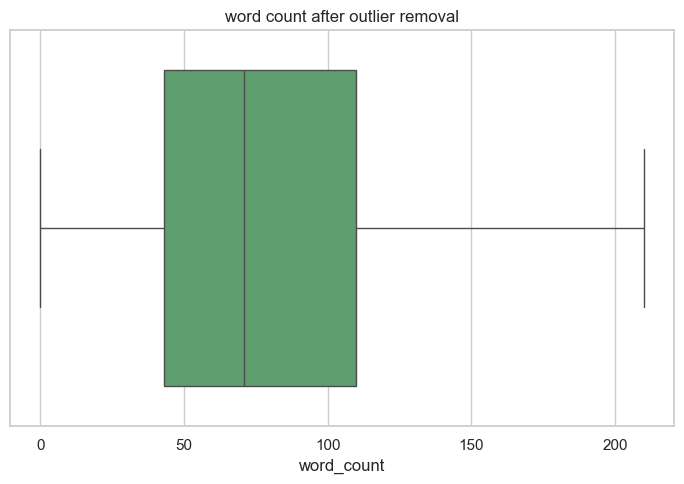

In [5]:
plt.figure(figsize=(7, 5))
sns.boxplot(x=df["word_count"], color="#4C72B0")
plt.title("word count before outlier removal")
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/outlier_before.png", dpi=150, bbox_inches="tight")
plt.show()

Q1 = df["word_count"].quantile(0.25)
Q3 = df["word_count"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

rows_before = len(df)
df = df[(df["word_count"] >= lower) & (df["word_count"] <= upper)].reset_index(drop=True)
print(f"IQR bounds: [{lower:.1f}, {upper:.1f}] words, removed {rows_before - len(df)} rows")

plt.figure(figsize=(7, 5))
sns.boxplot(x=df["word_count"], color="#55A868")
plt.title("word count after outlier removal")
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/outlier_after.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.4 Encoding categorical variables

The label is already 0/1, so it is label encoded. Review length is split into three equal groups (short, medium, long) and one-hot encoded.

label
1    150055
0    149928
Name: count, dtype: int64
   word_count length_category  length_short  length_medium  length_long
0         106            long         False          False         True
1          52           short          True          False        False
2          74          medium         False           True        False
3          43           short          True          False        False
4          74          medium         False           True        False


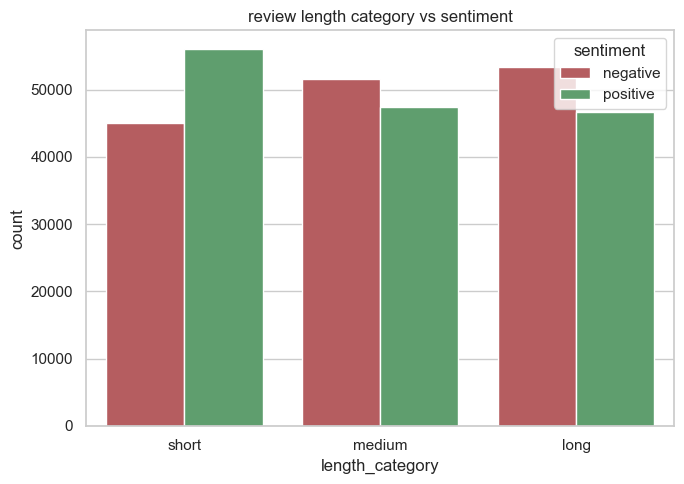

In [6]:
print(df["label"].value_counts())

df["length_category"] = pd.qcut(df["word_count"], q=3, labels=["short", "medium", "long"])
one_hot = pd.get_dummies(df["length_category"], prefix="length")
df = pd.concat([df, one_hot], axis=1)
print(df[["word_count", "length_category"] + list(one_hot.columns)].head())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="length_category", hue="label", palette=["#C44E52", "#55A868"])
plt.title("review length category vs sentiment")
plt.legend(title="sentiment", labels=["negative", "positive"])
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/length_category_by_sentiment.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.5 Normalization

`word_count` and the number of words in the review title (the text before the first ":") are scaled to the range 0-1 with MinMaxScaler.

   word_count  word_count_scaled  title_word_count  title_word_count_scaled
0         106           0.504762                 5                 0.142857
1          52           0.247619                 1                 0.028571
2          74           0.352381                 2                 0.057143
3          43           0.204762                 2                 0.057143
4          74           0.352381                 3                 0.085714


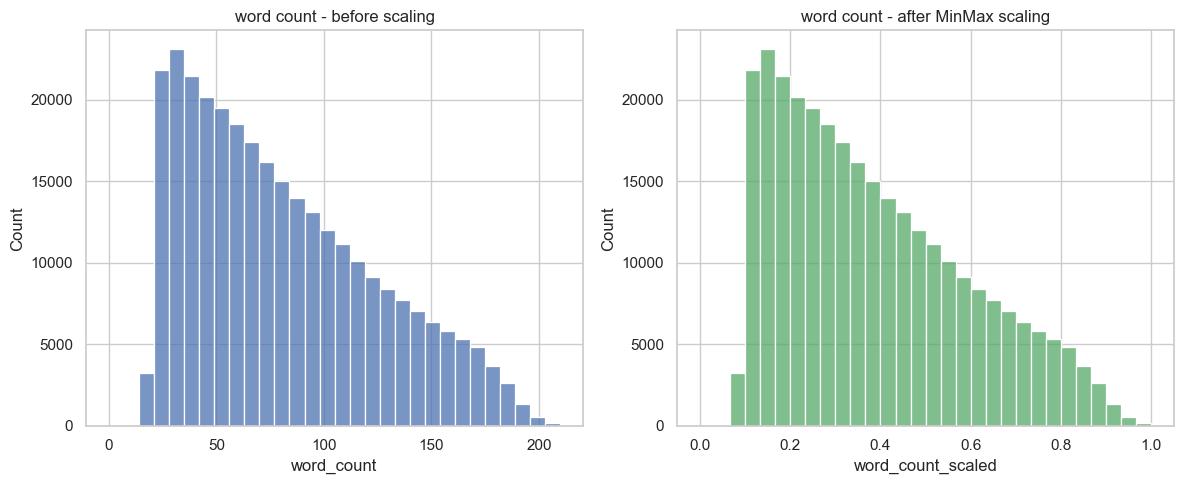

In [7]:
df["title_word_count"] = df["text"].str.split(":").str[0].str.split().str.len()

scaler = MinMaxScaler()
df[["word_count_scaled", "title_word_count_scaled"]] = scaler.fit_transform(
    df[["word_count", "title_word_count"]]
)
print(df[["word_count", "word_count_scaled", "title_word_count", "title_word_count_scaled"]].head())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df["word_count"], bins=30, ax=axes[0], color="#4C72B0")
axes[0].set_title("word count - before scaling")
sns.histplot(df["word_count_scaled"], bins=30, ax=axes[1], color="#55A868")
axes[1].set_title("word count - after MinMax scaling")
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/normalization_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.6 Tokenization and stop-word removal

`processed_text` is the cleaned text without stop words and very short words. `clean_text` still has the stop words (for example "not"), so both versions are compared later in the model section.

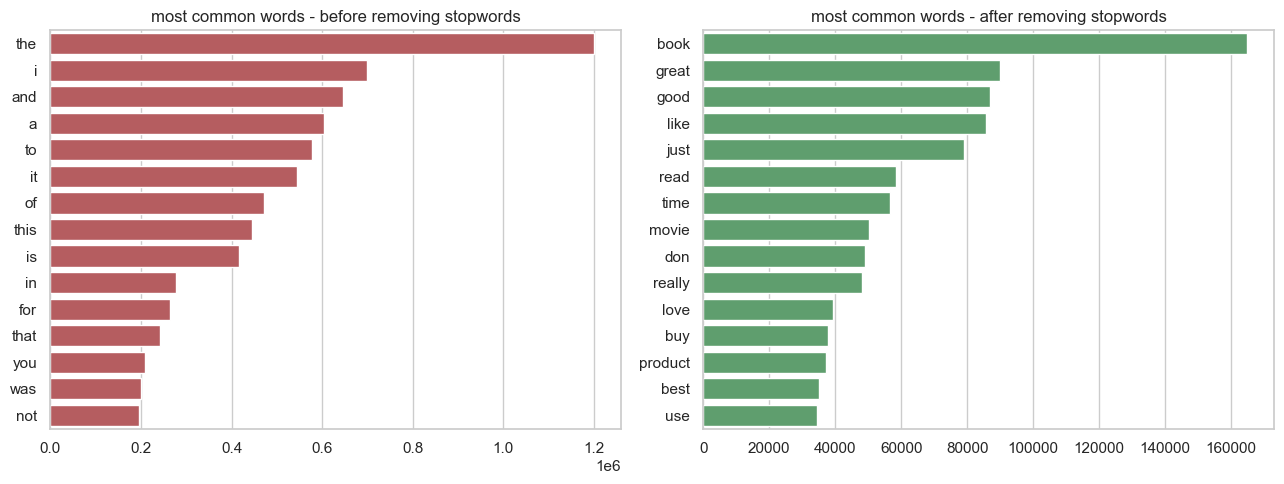

,clean_text,processed_text
0,works but not as advertised i bought one of th...,works advertised bought chargers instructions ...
1,disappointed i read the reviews made my purcha...,disappointed read reviews purchase disappointe...
2,very frustrating my three year old son was ver...,frustrating year old son excited attempts play...
3,kitchen tv i bought this to replace a tube tv ...,kitchen bought replace tube kitchen gained lar...
4,homer or moses an extremely helpful gem on a c...,homer moses extremely helpful gem complex subj...


In [8]:
df["tokens"] = df["clean_text"].str.split()
df["tokens_no_stopwords"] = df["tokens"].apply(
    lambda words: [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2]
)
df["processed_text"] = df["tokens_no_stopwords"].apply(lambda words: " ".join(words))

def most_common_words(list_of_token_lists, n=15):
    counts = Counter()
    for tokens in list_of_token_lists:
        counts.update(tokens)
    return counts.most_common(n)

before_words = most_common_words(df["tokens"])
after_words = most_common_words(df["tokens_no_stopwords"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(x=[c for _, c in before_words], y=[w for w, _ in before_words], ax=axes[0], color="#C44E52")
axes[0].set_title("most common words - before removing stopwords")
sns.barplot(x=[c for _, c in after_words], y=[w for w, _ in after_words], ax=axes[1], color="#55A868")
axes[1].set_title("most common words - after removing stopwords")
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/top_words_before_after_stopwords.png", dpi=150, bbox_inches="tight")
plt.show()

# the token lists use a lot of memory and are not needed any more
df = df.drop(columns=["tokens", "tokens_no_stopwords"])
df[["clean_text", "processed_text"]].head()

### 2.7 TF-IDF and PCA

The processed text is turned into 300 TF-IDF features, standardized and reduced to 2 components with PCA. This is only used to visualize how the two classes look.

TF-IDF shape: (299983, 300)
variance explained by 2 components: 0.0189296750581191


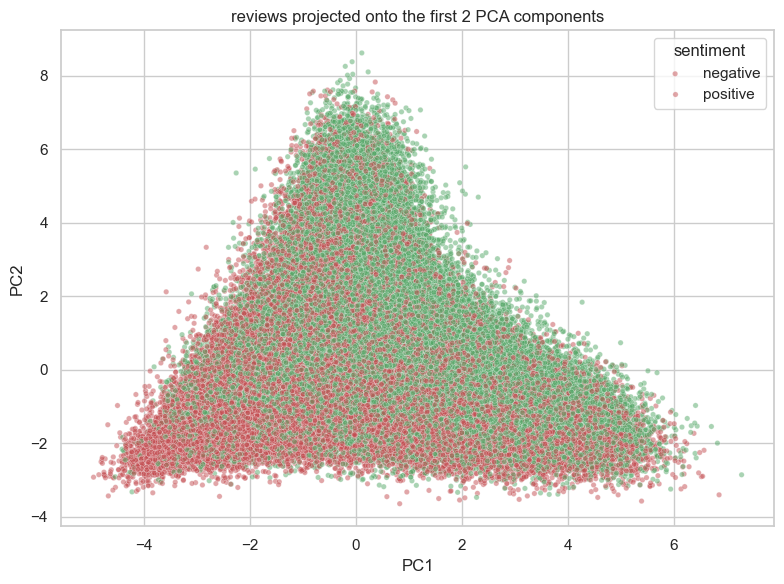

In [9]:
tfidf = TfidfVectorizer(max_features=300, min_df=3)
X_tfidf = tfidf.fit_transform(df["processed_text"])
print("TF-IDF shape:", X_tfidf.shape)

X_scaled = StandardScaler().fit_transform(X_tfidf.toarray())
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
print("variance explained by 2 components:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["label"],
                palette=["#C44E52", "#55A868"], alpha=0.5, s=15)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("reviews projected onto the first 2 PCA components")
plt.legend(title="sentiment", labels=["negative", "positive"])
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/pca_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

# free memory
X_tfidf = None
X_scaled = None

## 3. Train/test split

The data is split 80/20 with stratification (random_state=42). A 100,000 review subset of the training data (`X_dev`) is used for cross validation and tuning so that it runs in a reasonable time. The final model is trained on the full training set.

In [10]:
X = df[["text", "clean_text", "processed_text", "length_category"]]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_dev, _, y_dev, _ = train_test_split(
    X_train, y_train, train_size=100000, stratify=y_train, random_state=42
)

print("train:", len(X_train), "| test:", len(X_test), "| dev subset:", len(X_dev))
print("positive share (train / test / dev):", round(y_train.mean(), 4),
      round(y_test.mean(), 4), round(y_dev.mean(), 4))

train: 239986 | test: 59997 | dev subset: 100000
positive share (train / test / dev): 0.5002 0.5002 0.5002


## 4. Baseline and preprocessing variants

A Linear SVM (`LinearSVC`) with TF-IDF is tested with 5-fold stratified cross validation on the development subset. Four variants are compared: `processed_text` or `clean_text`, each with unigrams only or unigrams + bigrams. The baseline is `processed_text` with unigrams.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def run_cv(text_col, ngram, C=1.0, max_features=50000):
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=ngram, max_features=max_features)),
        ("svm", LinearSVC(C=C, random_state=42)),
    ])
    start = time.time()
    s = cross_validate(pipe, X_dev[text_col], y_dev, cv=cv,
                       scoring=["accuracy", "f1"], n_jobs=5)
    return {"text_column": text_col,
            "ngram_range": str(ngram),
            "cv_accuracy": round(float(s["test_accuracy"].mean()), 4),
            "cv_f1": round(float(s["test_f1"].mean()), 4),
            "cv_std": round(float(s["test_f1"].std()), 4),
            "time_s": round(time.time() - start, 1)}

results = []
for col in ["processed_text", "clean_text"]:
    for ngram in [(1, 1), (1, 2)]:
        results.append(run_cv(col, ngram))

variants_df = pd.DataFrame(results).sort_values("cv_f1", ascending=False)
variants_df

,text_column,ngram_range,cv_accuracy,cv_f1,cv_std,time_s
3,clean_text,"(1, 2)",0.9147,0.9148,0.0012,22.8
2,clean_text,"(1, 1)",0.8906,0.8906,0.0015,8.5
1,processed_text,"(1, 2)",0.8851,0.8855,0.0014,15.8
0,processed_text,"(1, 1)",0.8729,0.8732,0.0013,7.2


**Observations (section 4)**

- The baseline (`processed_text`, unigrams) gives a CV F1 of 0.8732. Every other variant is better, and the fold standard deviation is only 0.0013 to 0.0015, so the gaps are real.
- Keeping the stop words helps. `clean_text` beats `processed_text` by 1.74 points with unigrams (0.8906 vs 0.8732) and by 2.93 points with bigrams (0.9148 vs 0.8855). Words such as "not" carry sentiment, so removing them loses information.
- Bigrams help as well: +2.42 points on `clean_text` and +1.23 points on `processed_text`. Phrases like "not good" are captured only when bigrams are used.
- `clean_text` with bigrams is the best variant (CV F1 0.9148), a gain of 4.16 points over the baseline. It takes longer to train (22.8 s vs 7.2 s) because the feature space is larger.

## 5. Hyperparameter tuning

GridSearchCV is run on the best variant (`clean_text`, unigrams + bigrams). The parameters tuned are the vocabulary size, sublinear tf and C.

In [12]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("svm", LinearSVC(random_state=42)),
])

param_grid = {
    "tfidf__max_features": [100000, 300000],
    "tfidf__sublinear_tf": [True, False],
    "svm__C": [0.1, 0.3, 1.0],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1",
                    n_jobs=6, verbose=1, return_train_score=True)

start = time.time()
grid.fit(X_dev["clean_text"], y_dev)
print(f"time: {(time.time() - start) / 60:.1f} min")
print("best params:", grid.best_params_)
print(f"best CV F1: {grid.best_score_:.4f}")

cv_table = pd.DataFrame(grid.cv_results_)[[
    "param_tfidf__max_features", "param_tfidf__sublinear_tf", "param_svm__C",
    "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values("rank_test_score")
cv_table.round(4)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
time: 5.4 min
best params: {'svm__C': 0.3, 'tfidf__max_features': 100000, 'tfidf__sublinear_tf': True}
best CV F1: 0.9211


,param_tfidf__max_features,param_tfidf__sublinear_tf,param_svm__C,mean_train_score,mean_test_score,std_test_score,rank_test_score
4,100000,True,0.3,0.9752,0.9211,0.0002,1
10,300000,True,1.0,0.9981,0.9203,0.0010,2
6,300000,True,0.3,0.9816,0.9202,0.0005,3
11,300000,False,1.0,0.9978,0.9196,0.0013,4
5,100000,False,0.3,0.9739,0.9195,0.0010,5
7,300000,False,0.3,0.9805,0.9189,0.0006,6
8,100000,True,1.0,0.9951,0.9186,0.0010,7
9,100000,False,1.0,0.9943,0.9177,0.0007,8
0,100000,True,0.1,0.9503,0.9157,0.0005,9
2,300000,True,0.1,0.9542,0.9143,0.0004,10


**Observations (section 5)**

- Tuning raised the CV F1 from 0.9148 (C=1.0, 50k features) to 0.9211, a gain of 0.63 points. The best setting is C=0.3, 100,000 features and `sublinear_tf=True`.
- The top results are very close (0.9211, 0.9203 and 0.9202 for ranks 1 to 3), so the choice of vocabulary size matters little. C has the larger effect.
- C=0.1 under-fits (CV F1 0.9128 to 0.9157, train score about 0.95). Large C over-fits: with C=1.0 and 300,000 features the train score is 0.9981 but the CV score is only 0.9203. The gap between train and CV score is 0.0778 there, against 0.0541 for the best model.
- `sublinear_tf=True` was better than `False` in every matching pair of settings.

## 6. Final model and test evaluation

The best parameters are used to train the model on the full training set. The test set is only used here, once.

training time: 42.4 s
Accuracy : 0.9309
Precision: 0.9302
Recall   : 0.9319
F1 Score : 0.9310
ROC AUC  : 0.9793

              precision    recall  f1-score   support

    Negative     0.9317    0.9300    0.9308     29986
    Positive     0.9302    0.9319    0.9310     30011

    accuracy                         0.9309     59997
   macro avg     0.9309    0.9309    0.9309     59997
weighted avg     0.9309    0.9309    0.9309     59997

Confusion matrix:
 [[27886  2100]
 [ 2045 27966]]


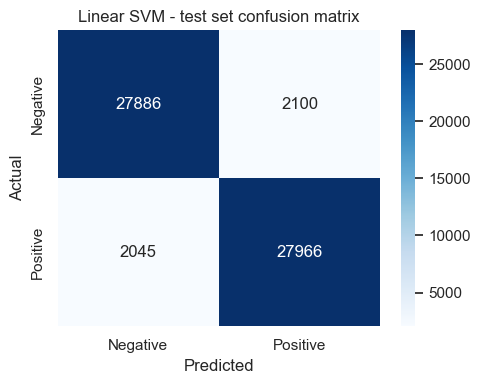

In [13]:
best = grid.best_params_
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2),
                              max_features=best["tfidf__max_features"],
                              sublinear_tf=best["tfidf__sublinear_tf"])),
    ("svm", LinearSVC(C=best["svm__C"], random_state=42)),
])

start = time.time()
final_model.fit(X_train["clean_text"], y_train)
svm_train_time = round(time.time() - start, 1)
print(f"training time: {svm_train_time} s")

y_pred = final_model.predict(X_test["clean_text"])
scores = final_model.decision_function(X_test["clean_text"])

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, scores)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {auc:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=4))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Linear SVM - test set confusion matrix")
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/svm_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations (section 6)**

- On the held-out test set of 59,997 reviews the final model reaches accuracy 0.9309, precision 0.9302, recall 0.9319, F1 0.9310 and ROC AUC 0.9793.
- The test F1 (0.9310) is 0.99 points higher than the CV F1 (0.9211). A likely reason is that each CV fold trained on about 80,000 reviews while the final model used all 239,986, so there is no sign of over-fitting to the test set.
- The errors are balanced: 2,100 negative reviews were predicted as positive and 2,045 positive reviews as negative (4,145 errors in total, 6.91%). Precision and recall are almost equal for both classes, so the model does not favour either class.
- The final model trained in 42.4 s.

## 7. SVC with different kernels and C

`SVC` is too slow for the full data, so linear and RBF kernels with different C values are compared on a small subset of 8,000 training reviews (80% train, 20% test). The number of support vectors is also checked.

In [14]:
X_small, _, y_small, _ = train_test_split(
    X_train["clean_text"], y_train, train_size=8000, stratify=y_train, random_state=42
)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(
    X_small, y_small, test_size=0.2, stratify=y_small, random_state=42
)

vec = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), sublinear_tf=True)
Xs_tr_v = vec.fit_transform(Xs_tr)
Xs_te_v = vec.transform(Xs_te)
print("train:", Xs_tr_v.shape, "| test:", Xs_te_v.shape)

svc_rows = []
for kernel in ["linear", "rbf"]:
    for C in [0.1, 1, 10]:
        start = time.time()
        m = SVC(kernel=kernel, C=C, random_state=42).fit(Xs_tr_v, ys_tr)
        pred = m.predict(Xs_te_v)
        svc_rows.append({
            "kernel": kernel,
            "C": C,
            "support_vectors": int(m.n_support_.sum()),
            "accuracy": round(accuracy_score(ys_te, pred), 4),
            "f1": round(f1_score(ys_te, pred), 4),
            "roc_auc": round(roc_auc_score(ys_te, m.decision_function(Xs_te_v)), 4),
            "time_s": round(time.time() - start, 1),
        })

svc_df = pd.DataFrame(svc_rows)
svc_df

train: (6400, 20000) | test: (1600, 20000)


,kernel,C,support_vectors,accuracy,f1,roc_auc,time_s
0,linear,0.1,5840,0.8525,0.8479,0.9282,26.1
1,linear,1.0,4051,0.8756,0.8754,0.9467,18.9
2,linear,10.0,3833,0.8656,0.8642,0.9393,21.5
3,rbf,0.1,6399,0.7450,0.7916,0.9124,29.7
4,rbf,1.0,5626,0.8794,0.8781,0.9474,27.3
5,rbf,10.0,5687,0.8794,0.8791,0.9497,28.5


**Observations (section 7)**

- This experiment uses only 8,000 reviews (1,600 for testing), so the scores are lower than the full model and the small differences should not be over-interpreted.
- The best linear result is C=1.0 (F1 0.8754). C=0.1 under-fits (0.8479) and C=10 is slightly worse than C=1 (0.8642), which agrees with the over-fitting seen in section 5.
- RBF with C=1 and C=10 reached F1 0.8781 and 0.8791, which is only about 0.3 to 0.4 points above the best linear kernel. On 1,600 test reviews this difference is too small to claim an advantage. RBF with C=0.1 under-fits badly (accuracy 0.7450, with 6,399 of 6,400 training points as support vectors).
- The RBF kernel gave no clear gain on text, so the Linear SVM is a sensible choice. It is also much faster, because `SVC` cannot be used on the full training set.

## 8. Model interpretation and error analysis

The biggest SVM coefficients show which words and phrases push a review towards each class. The errors are also checked by review length, and the most confident mistakes are printed.

Top negative features:
        feature  weight
           not  -5.893
 disappointing  -5.590
     not worth  -5.040
         worst  -4.850
          poor  -4.758
  disappointed  -4.691
        boring  -4.681
disappointment  -4.660
      horrible  -4.195
     two stars  -4.109
 not recommend  -4.095
      terrible  -3.916
      not very  -3.915
      not good  -3.904
        poorly  -3.699

Top positive features:
          feature  weight
           great   6.587
       excellent   5.315
         awesome   4.259
            good   3.759
         not bad   3.487
            best   3.469
         my only   3.372
         perfect   3.327
       wonderful   3.273
         amazing   3.234
not disappointed   3.194
     better than   3.003
         is must   2.915
       fantastic   2.863
       love this   2.843


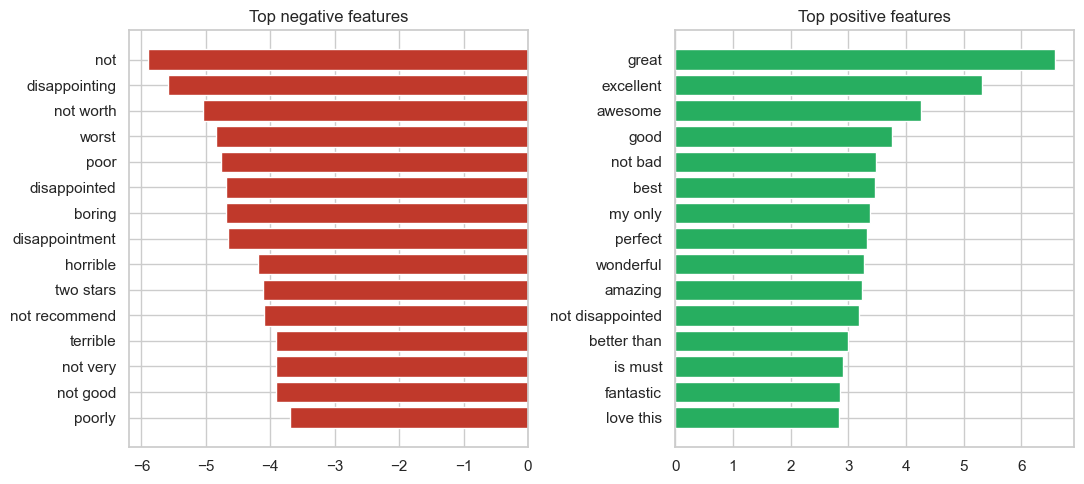


Total errors: 4145 of 59997

Error rate by review length:
                   mean   sum  count
length_category                     
long             0.0783  1575  20122
medium           0.0673  1327  19704
short            0.0616  1243  20171

Most confident mistakes:

True=1  Pred=0  Confidence=2.97
bad set: The next to last dvd didn't work at all and now I have to wait forever to get another set.. Poor quality is not good business.

True=0  Pred=1  Confidence=2.66
Another great book from JoAnn Mapson: JoAnn writes great stories with believeable characters--people you know or want to know. Her stories are hard to put down. You can feel their pain and their joy and her endings leave you wanting more.This is a story about new beginnings, old pain and good friend

True=1  Pred=0  Confidence=2.45
IT SUCKS: THIS GAME REALLY SUCKS CUZ THE PLAYERS ARE WEAK AND STUPID.I M REALLY TIRED OF ALL THESE RETARDED PEOLPLE LIKE LINK.DON T BUY THIS GAME IT SUCKS!!!!!!!!!!!!!!!!!!!!!!!!!!

True=0  Pred

In [15]:
tfidf_fit = final_model.named_steps["tfidf"]
svm_fit = final_model.named_steps["svm"]
names = np.array(tfidf_fit.get_feature_names_out())
coefs = svm_fit.coef_[0]
order = np.argsort(coefs)

top_neg = pd.DataFrame({"feature": names[order[:15]], "weight": coefs[order[:15]]})
top_pos = pd.DataFrame({"feature": names[order[-15:][::-1]], "weight": coefs[order[-15:][::-1]]})
print("Top negative features:\n", top_neg.round(3).to_string(index=False))
print("\nTop positive features:\n", top_pos.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh(top_neg["feature"][::-1], top_neg["weight"][::-1], color="#c0392b")
axes[0].set_title("Top negative features")
axes[1].barh(top_pos["feature"][::-1], top_pos["weight"][::-1], color="#27ae60")
axes[1].set_title("Top positive features")
plt.tight_layout()
plt.savefig(f"{EDA_DIR}/svm_top_features.png", dpi=150, bbox_inches="tight")
plt.show()

err = pd.DataFrame({
    "true": y_test.values,
    "pred": y_pred,
    "score": scores,
    "length_category": X_test["length_category"].astype(str).values,
    "text": X_test["text"].values,
})
err["wrong"] = err["true"] != err["pred"]
print("\nTotal errors:", err["wrong"].sum(), "of", len(err))
print("\nError rate by review length:")
print(err.groupby("length_category")["wrong"].agg(["mean", "sum", "count"]).round(4))

wrong = err[err["wrong"]].copy()
wrong["confidence"] = wrong["score"].abs()
print("\nMost confident mistakes:")
for _, r in wrong.sort_values("confidence", ascending=False).head(5).iterrows():
    print(f"\nTrue={r['true']}  Pred={r['pred']}  Confidence={r['confidence']:.2f}")
    print(r["text"][:300])

**Observations (section 8)**

- The strongest negative features are "not" (-5.893), "disappointing", "not worth", "worst" and "poor". The strongest positive features are "great" (6.587), "excellent", "awesome" and "good".
- The bigrams handle negation. "not worth", "not recommend", "not good" and "not very" are negative, while "not bad" and "not disappointed" are positive. This explains why bigrams improved the score in section 4.
- The error rate rises with review length: 6.16% for short, 6.73% for medium and 7.83% for long reviews. Long reviews are more likely to contain both praise and complaints.
- Several of the most confident mistakes look like wrong labels rather than model faults. For example, "IT SUCKS ... DON T BUY THIS GAME" is labelled positive, and "Another great book" and "Outstanding device" are labelled negative. This suggests some label noise in the dataset, which would limit the accuracy any model can reach.
- Some other mistakes are mixed reviews (for example the warranty review that praises Amazon's service but describes a faulty product).

## 9. Summary of results

All results are collected in one table and saved with the final model in `results/outputs/`.

In [16]:
rows = []
for _, r in variants_df.iterrows():
    name = f"{r['text_column']}, ngram {r['ngram_range']}, C=1.0, 50k features"
    if r["text_column"] == "processed_text" and r["ngram_range"] == "(1, 1)":
        name = "BASELINE: " + name
    rows.append({"model_variant": name,
                 "validation": "5-fold CV (100k dev subset)",
                 "accuracy": r["cv_accuracy"], "f1": r["cv_f1"], "roc_auc": None})

rows.append({"model_variant": f"Tuned (GridSearchCV): {grid.best_params_}",
             "validation": "5-fold CV (100k dev subset)",
             "accuracy": None, "f1": round(grid.best_score_, 4), "roc_auc": None})
rows.append({"model_variant": "FINAL: LinearSVC on full training set",
             "validation": f"Held-out test set ({len(X_test):,} reviews)",
             "accuracy": round(acc, 4), "f1": round(f1, 4), "roc_auc": round(auc, 4)})

summary = pd.DataFrame(rows)
summary.to_csv(f"{OUT_DIR}/svm_model_summary.csv", index=False)
cv_table.to_csv(f"{OUT_DIR}/svm_gridsearch_results.csv", index=False)
svc_df.to_csv(f"{OUT_DIR}/svc_lab04_experiment.csv", index=False)
joblib.dump(final_model, f"{OUT_DIR}/svm_final_model.joblib")

pd.set_option("display.max_colwidth", 90)
summary

,model_variant,validation,accuracy,f1,roc_auc
0,"clean_text, ngram (1, 2), C=1.0, 50k features",5-fold CV (100k dev subset),0.9147,0.9148,NaN
1,"clean_text, ngram (1, 1), C=1.0, 50k features",5-fold CV (100k dev subset),0.8906,0.8906,NaN
2,"processed_text, ngram (1, 2), C=1.0, 50k features",5-fold CV (100k dev subset),0.8851,0.8855,NaN
3,"BASELINE: processed_text, ngram (1, 1), C=1.0, 50k features",5-fold CV (100k dev subset),0.8729,0.8732,NaN
4,"Tuned (GridSearchCV): {'svm__C': 0.3, 'tfidf__max_features': 100000, 'tfidf__sublinear...",5-fold CV (100k dev subset),NaN,0.9211,NaN
5,FINAL: LinearSVC on full training set,"Held-out test set (59,997 reviews)",0.9309,0.9310,0.9793


### 9.1 Save the final result
The final test result is saved to `results/final_metrics/Linear_SVM.csv` for the group comparison.

In [17]:
# save the final result for the group comparison (same format in all six notebooks)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
result = {
    "model": "Linear SVM", "student_id": "IT25102662",
    "accuracy": round(accuracy_score(y_test, y_pred), 4),
    "precision": round(precision_score(y_test, y_pred), 4),
    "recall": round(recall_score(y_test, y_pred), 4),
    "f1": round(f1_score(y_test, y_pred), 4),
    "f1_macro": round(f1_score(y_test, y_pred, average="macro"), 4),
    "roc_auc": round(roc_auc_score(y_test, scores), 4),
    "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    "cv_f1_mean": round(grid.best_score_, 4),
    "cv_f1_std": round(grid.cv_results_["std_test_score"][grid.best_index_], 4),
    "train_time_s": svm_train_time, "n_train": len(X_train),
    "best_params": str(grid.best_params_), "notes": "Tuned on 100k dev subset with 5-fold CV",
}
pd.DataFrame([result]).to_csv(os.path.join(METRICS_DIR, "Linear_SVM.csv"), index=False)
print("Saved:", os.path.join(METRICS_DIR, "Linear_SVM.csv"))

Saved: ../results/final_metrics\Linear_SVM.csv


## 10. Conclusion

A Linear SVM with TF-IDF was trained on a random sample of 300,000 Amazon reviews (299,983 after preprocessing: 239,986 for training and 59,997 for testing).

- Keeping stop words (`clean_text`) and using unigrams + bigrams gave the best features. Together they raised the CV F1 from 0.8732 (baseline) to 0.9148.
- GridSearchCV selected C=0.3, 100,000 features and `sublinear_tf=True` (CV F1 0.9211).
- The final model scored accuracy 0.9309, F1 0.9310 and ROC AUC 0.9793 on the held-out test set, with balanced errors on both classes.
- The RBF kernel did not give a clear improvement over the linear kernel in the small experiment, and `SVC` is too slow for the full data.

**Limitations.** Tuning used a 100,000 review subset and a limited grid. The SVC experiment used only 8,000 reviews. The model uses bag-of-words features, so it cannot understand sarcasm or long mixed reviews, and some errors appear to come from noisy labels.